# CEBRA representations and behavioural associations

This notebook reproduces the CEBRA analyses used in the paper from the saved three-dimensional embeddings.

The four experimental conditions are **rest**, **meditation**, **music**, and **movie**. For every participant and session, a linear classifier is fitted to the complete CEBRA trajectory and evaluated on those same time points. 

All inputs are read from the `data/` folder; all generated files are written to `outputs/`.

In [1]:
from pathlib import Path
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from scipy.stats import pearsonr, ttest_ind
from sklearn.metrics import accuracy_score
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT / 'analysis' / 'data').exists():
    ROOT = ROOT / 'analysis'
DATA = ROOT / 'data'
OUTPUT = ROOT / 'outputs'
OUTPUT.mkdir(exist_ok=True)

PHASES = ['rest', 'meditation', 'music', 'movie']
PHASE_LABELS = ['Rest', 'Meditation', 'Music', 'Movie']
PHASE_COLORS = dict(zip(PHASES, ['#ed2f92', '#2d348b', '#087437', '#f5a623']))
CONDITIONS = ['No psilocybin', 'Psilocybin']
SESSIONS = CONDITIONS

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## Load and validate the  data

The CEBRA embeddings are stored by participant ID. Compact metadata files provide the phase durations and the example activity traces required by the figures.


In [2]:
required = [
    'no_psilocybin_cebra_embeddings.pkl', 'psilocybin_cebra_embeddings.pkl',
    'phase_durations.csv', 'example_activity_PC209_psilocybin.npz',
    'silhouette_repeated_runs.csv', 'network_perturbation_confusion_matrices.npz',
    'MEQ30_MEAN.csv',
    'Additional_metrics.tsv', 'followup-1day.tsv'
]
missing = [name for name in required if not (DATA / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing paper inputs: {missing}')

with open(DATA / 'no_psilocybin_cebra_embeddings.pkl', 'rb') as f:
    no_psilocybin_saved = pickle.load(f)
with open(DATA / 'psilocybin_cebra_embeddings.pkl', 'rb') as f:
    psilocybin_saved = pickle.load(f)

if not isinstance(no_psilocybin_saved, dict) or not isinstance(psilocybin_saved, dict):
    raise TypeError('Saved embedding files must be dictionaries keyed by participant ID.')

meq = pd.read_csv(DATA / 'MEQ30_MEAN.csv', encoding='utf-8-sig')
meq['Participant'] = meq['participant_id'].str.extract(r'(PC\d+)')[0]
meq_map = meq.drop_duplicates('Participant').set_index('Participant')['MEQ30_MEAN']

participants = sorted(set(no_psilocybin_saved) & set(psilocybin_saved))
if len(participants) != 54:
    raise ValueError(f'Expected 54 common participants, found {len(participants)}.')
if set(no_psilocybin_saved) != set(psilocybin_saved):
    raise ValueError('Participant IDs differ between the two saved embedding files.')
if meq_map.reindex(participants).isna().any():
    raise ValueError('Missing MEQ values for one or more participants.')

embeddings = {
    'No psilocybin': {
        pid: np.asarray(no_psilocybin_saved[pid], dtype=float)
        for pid in participants
    },
    'Psilocybin': {
        pid: np.asarray(psilocybin_saved[pid], dtype=float)
        for pid in participants
    },
}

duration_table = pd.read_csv(DATA / 'phase_durations.csv')
duration_lookup = duration_table.set_index(['Participant', 'Condition'])

def phase_durations(pid, condition):
    try:
        row = duration_lookup.loc[(pid, condition)]
    except KeyError as exc:
        raise KeyError(f'Missing phase durations for {pid}, {condition}.') from exc
    return [int(row[phase]) for phase in PHASES]

with np.load(DATA / 'example_activity_PC209_psilocybin.npz') as saved_activity:
    example_activity = {phase: np.asarray(saved_activity[phase]) for phase in PHASES}

for condition in CONDITIONS:
    for pid in participants:
        expected_length = sum(phase_durations(pid, condition))
        embedding = embeddings[condition][pid]
        if embedding.shape != (expected_length, 3):
            raise ValueError(
                f'{pid}, {condition}: expected embedding shape '
                f'({expected_length}, 3), found {embedding.shape}.'
            )

print(f'Validated participant-keyed embeddings for {len(participants)} participants.')


Validated participant-keyed embeddings for 54 participants.


## Experimental time-series structure

An example recording illustrates the temporal concatenation used for each CEBRA trajectory. Traces are vertically offset for visibility; colour denotes the experimental condition.

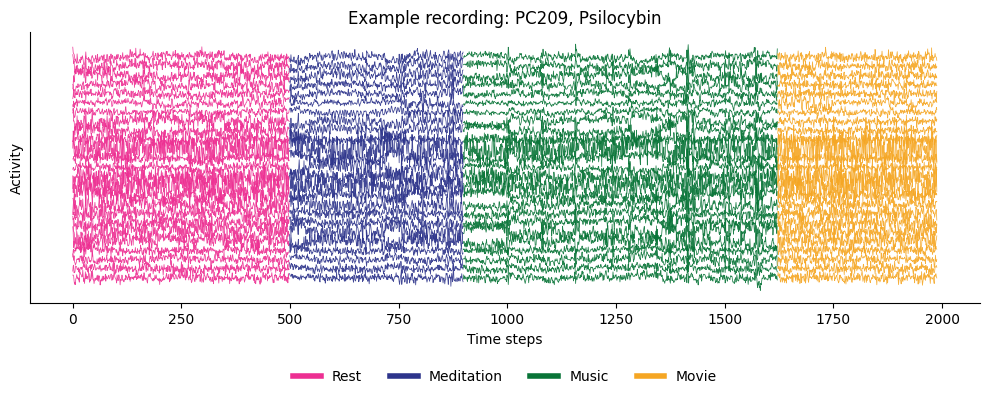

In [3]:
example_pid, example_session = 'PC209', 'Psilocybin'
phase_arrays = [example_activity[phase] for phase in PHASES]
fig, ax = plt.subplots(figsize=(10, 4.2))
start = 0
for phase, values in zip(PHASES, phase_arrays):
    stop = start + values.shape[1]
    traces = values[:25]
    scale = np.nanstd(traces) or 1.0
    for roi, trace in enumerate(traces):
        ax.plot(np.arange(start, stop), trace / scale + roi * 2.2,
                color=PHASE_COLORS[phase], lw=0.55, alpha=0.9)
    start = stop
ax.set(xlabel='Time steps', ylabel='Activity', title=f'Example recording: {example_pid}, {example_session}')
ax.set_yticks([])
ax.legend([Line2D([0], [0], color=PHASE_COLORS[p], lw=4) for p in PHASES],
          PHASE_LABELS, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.20))
fig.tight_layout()
fig.savefig(OUTPUT / 'figure_activity_time_series.png', dpi=300, bbox_inches='tight')
plt.show()

## Condition classification results

Classification is performed independently for every participant and session. 

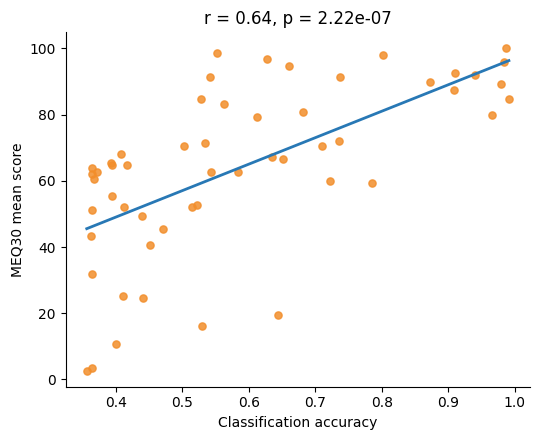

In [4]:
def phase_labels(durations):
    return np.concatenate([np.full(n, label, dtype=int)
                           for label, n in enumerate(durations)])

from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

linear_classifiers_dict = {
    0: OneVsRestClassifier(
        LogisticRegression(random_state=42, max_iter=1000)
    ),
    1: SVC(
        kernel='linear', C=0.025, class_weight='balanced',
        decision_function_shape='ovr',
    ),
}

classifier = linear_classifiers_dict[0]

def classification_accuracy(embedding, durations):
    labels = phase_labels(durations)
    fitted_classifier = clone(classifier)
    fitted_classifier.fit(embedding, labels)
    return float(accuracy_score(labels, fitted_classifier.predict(embedding)))


rows = []
for pid in participants:
    accuracy = classification_accuracy(
        embeddings['Psilocybin'][pid],
        phase_durations(pid, 'Psilocybin'),
    )
    rows.append({'Participant': pid, 'Session': 'Psilocybin',
                 'Accuracy': accuracy, 'MEQ': float(meq_map[pid])})
results = pd.DataFrame(rows)
results.to_csv(OUTPUT / 'classification_subject_results.csv', index=False)

subset = results.copy()
r, p = pearsonr(subset['Accuracy'], subset['MEQ'])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(subset['Accuracy'], subset['MEQ'], s=27, color='#f28e2b', alpha=0.85)
coef = np.polyfit(subset['Accuracy'], subset['MEQ'], 1)
xx = np.linspace(subset['Accuracy'].min(), subset['Accuracy'].max(), 200)
ax.plot(xx, np.polyval(coef, xx), color='#2878b5', lw=2)
ax.set(title=f'r = {r:.2f}, p = {p:.3g}',
       xlabel='Classification accuracy', ylabel='MEQ30 mean score')
fig.tight_layout()
fig.savefig(OUTPUT / 'figure_classification_accuracy_meq.png', dpi=300,
            bbox_inches='tight')
plt.show()

correlation_summary = pd.DataFrame([{
    'Session': 'Psilocybin', 'N': len(subset), 'PearsonR': round(r, 2),
    'PValue': p, 'MeanAccuracy': subset['Accuracy'].mean(),

}])
correlation_summary.to_csv(
    OUTPUT / 'classification_meq_correlations.csv', index=False
)


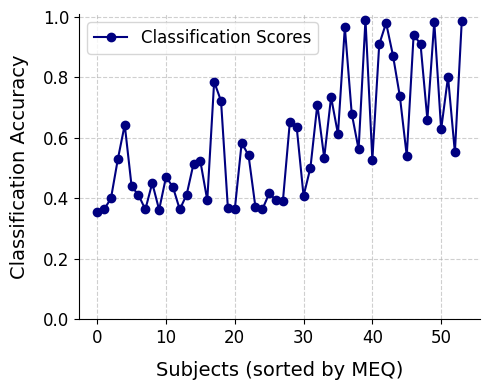

In [5]:
# Participants are sorted by increasing MEQ; exact MEQ ties retain their
# original left-to-right order from the published panel.
published_tie_priority = {
    'PC221': 0, 'PC028': 1,  # MEQ = 64.67
    'PC032': 0, 'PC025': 1,  # MEQ = 70.67
    'PC229': 0, 'PC026': 1,  # MEQ = 84.67
    'PC207': 0, 'PC029': 1,  # MEQ = 91.33
}

published_scores = results.assign(
    _published_tie_order=results['Participant'].map(published_tie_priority).fillna(0)
).sort_values(
    ['MEQ', '_published_tie_order', 'Participant']
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(
    published_scores['Accuracy'].to_numpy(),
    marker='o', linestyle='-', color='navy',
    label='Classification Scores',
)
ax.set_xlabel('Subjects (sorted by MEQ)', fontsize=14, labelpad=10)
ax.set_ylabel('Classification Accuracy', fontsize=14, labelpad=10)
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_ylim(0, 1.01)
fig.tight_layout()
fig.savefig(
    OUTPUT / 'figure_classification_accuracy_published_order.png',
    dpi=300, bbox_inches='tight',
)
plt.show()


## Representative CEBRA trajectories

CEBRA three-dimensional embeddings are shown for representative high- and low-MEQ participants, with the same phase colours in both sessions. PC206 is included as an additional as a particularly different subject with a high MEQ score.

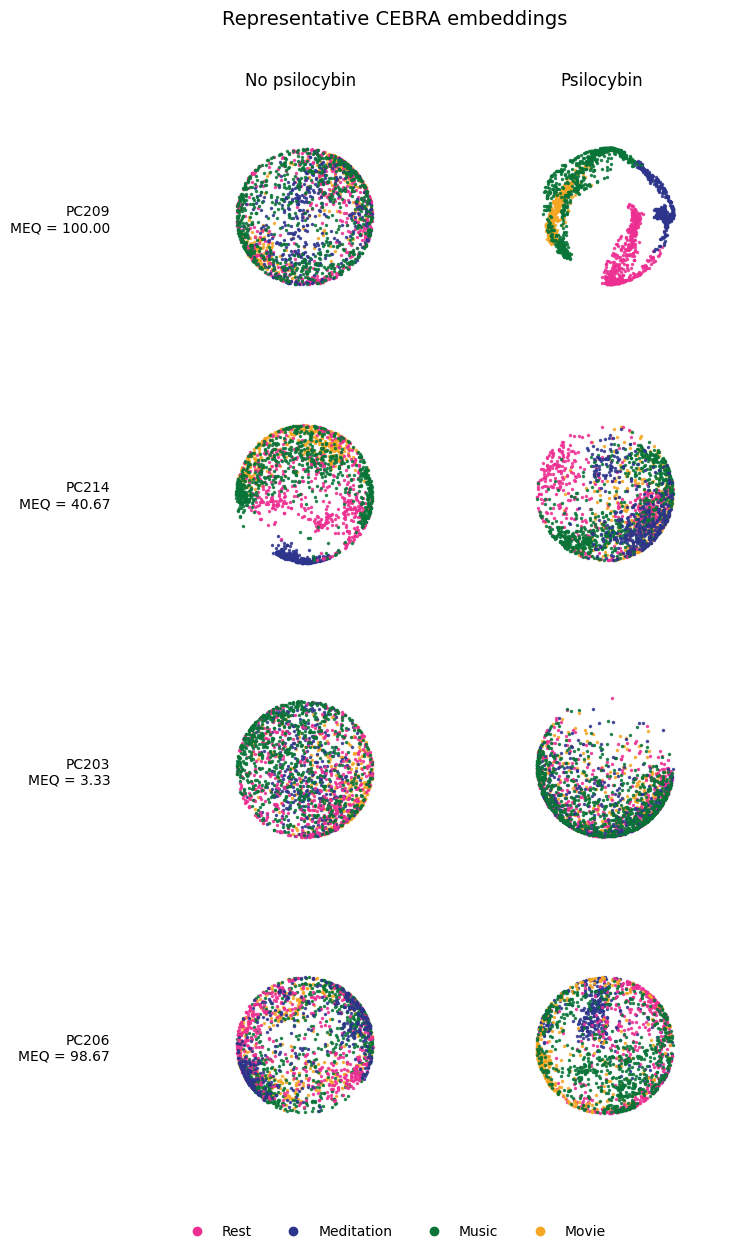

In [6]:
def scatter_embedding(ax, pid, session, point_size=2.0, alpha=0.8):
    embedding = embeddings[session][pid]
    labels = phase_labels(phase_durations(pid, session))
    for label, phase in enumerate(PHASES):
        points = embedding[labels == label]
        ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=point_size,
                   color=PHASE_COLORS[phase], alpha=alpha, depthshade=False, rasterized=True)
    ax.set_axis_off()
    ax.set_box_aspect((1, 1, 1))

representative = ['PC209', 'PC214','PC203', 'PC206']
n_representative = len(representative)
fig = plt.figure(figsize=(8, 3.0 * n_representative + 0.6))
for row, pid in enumerate(representative):
    for col, session in enumerate(SESSIONS):
        ax = fig.add_subplot(n_representative, 2, row * 2 + col + 1, projection='3d')
        scatter_embedding(ax, pid, session, point_size=2.2)
        if pid == 'PC214' and session == 'Psilocybin':
            ax.view_init(elev=35, azim=240)
        if row == 0:
            ax.set_title('No psilocybin' if session == 'No psilocybin' else 'Psilocybin', pad=3)
        if col == 0:
            ax.text2D(-0.23, 0.5, f'{pid}\nMEQ = {meq_map[pid]:.2f}', transform=ax.transAxes,
                      va='center', ha='right', fontsize=10)
fig.legend([Line2D([0], [0], marker='o', linestyle='', color=PHASE_COLORS[p]) for p in PHASES],
           PHASE_LABELS, frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, 0.01))
fig.suptitle('Representative CEBRA embeddings', y=0.995, fontsize=14)
fig.tight_layout(rect=(0, 0.055, 1, 0.985))
fig.savefig(OUTPUT / 'figure_representative_embeddings.png', dpi=300, bbox_inches='tight')
plt.show()

## Participants with low and high classification accuracy

The six participants in the low-accuracy group and the six participants in the high-accuracy group are shown for both sessions. Within each group, participants are arranged from left to right by increasing MEQ score.

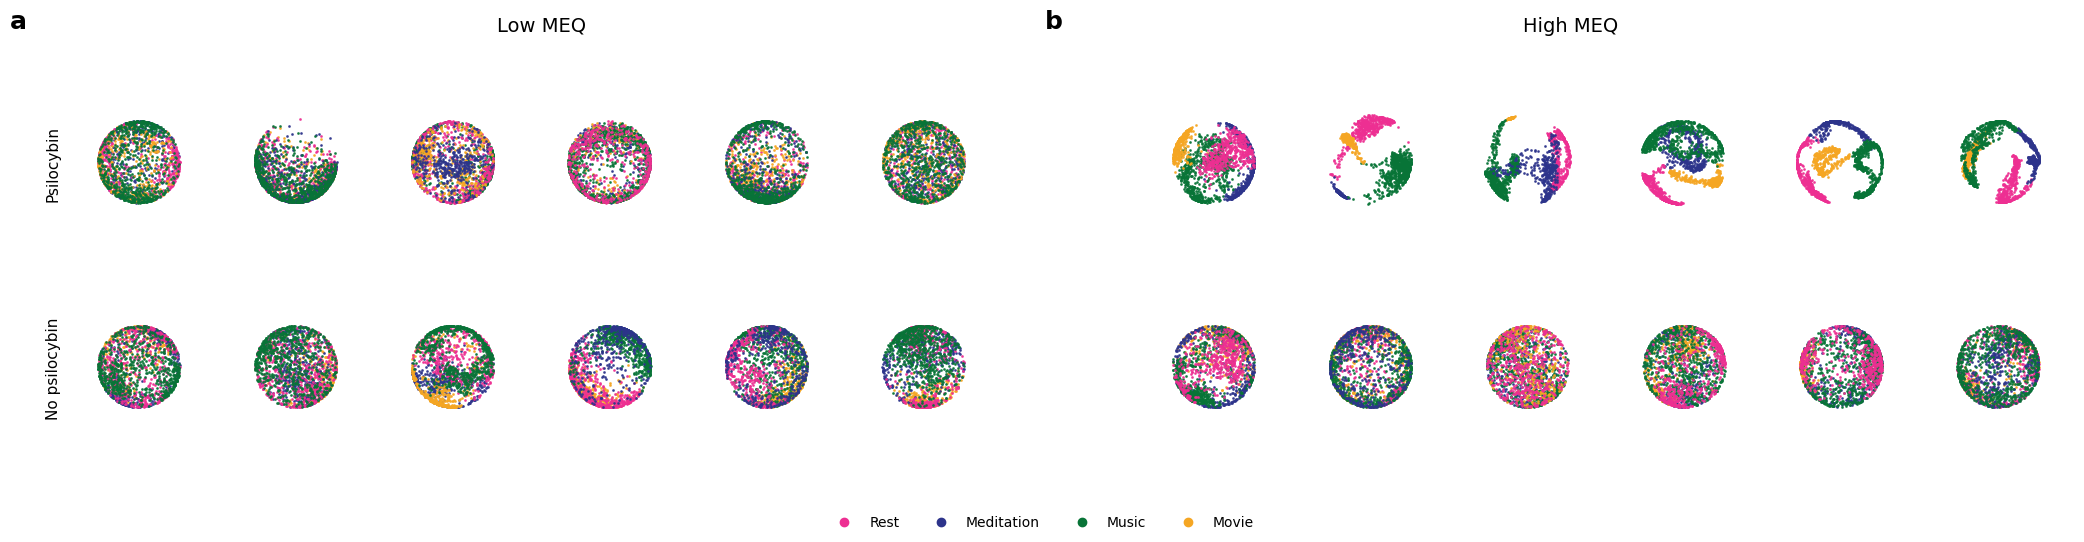

In [7]:
# Participant sets used for the low- and high-accuracy comparisons.
# Stored indices refer to the lexicographically ordered participant list.
low_accuracy_indices = [4, 26, 45, 8, 19, 27]
high_accuracy_indices = [39, 51, 35, 22, 53, 32]

low_accuracy_ids = sorted([participants[i] for i in low_accuracy_indices], key=meq_map.get)
high_accuracy_ids = sorted([participants[i] for i in high_accuracy_indices], key=meq_map.get)
shown = low_accuracy_ids + high_accuracy_ids

fig = plt.figure(figsize=(21, 5.4))
grid = fig.add_gridspec(2, 13, width_ratios=[1] * 6 + [0.85] + [1] * 6,
                        left=0.035, right=0.995, bottom=0.13, top=0.88,
                        wspace=0.0, hspace=0.02)
for row, session in enumerate(['Psilocybin', 'No psilocybin']):
    for col, pid in enumerate(shown):
        grid_col = col if col < 6 else col + 1
        ax = fig.add_subplot(grid[row, grid_col], projection='3d')
        scatter_embedding(ax, pid, session, point_size=1.05, alpha=0.8)
    
        if col == 0:
            ax.text2D(-0.08, 0.5, session, transform=ax.transAxes,
                      rotation=90, va='center', fontsize=11)
fig.text(0.265, 0.94, 'Low MEQ', ha='center', fontsize=14)
fig.text(0.755, 0.94, 'High MEQ', ha='center', fontsize=14)
fig.text(0.012, 0.945, 'a', fontsize=18, fontweight='bold')
fig.text(0.505, 0.945, 'b', fontsize=18, fontweight='bold')
fig.legend([Line2D([0], [0], marker='o', linestyle='', color=PHASE_COLORS[p]) for p in PHASES],
           PHASE_LABELS, frameon=False, ncol=4, loc='lower center')
fig.savefig(OUTPUT / 'figure_low_high_accuracy_embeddings.png', dpi=300, bbox_inches='tight')
plt.show()

## Condition-specific silhouette scores

Condition separation was also quantified with cosine-distance silhouette scores. The six participants at each group were evaluated separately for the No psilocybin and Psilocybin sessions. Each point is a participant's mean condition-specific silhouette score across ten repeated CEBRA fits. Brackets compare the low- and high-MEQ groups using two-sided Welch tests; asterisks denote *p* < 0.05 and NS denotes a non-significant comparison.

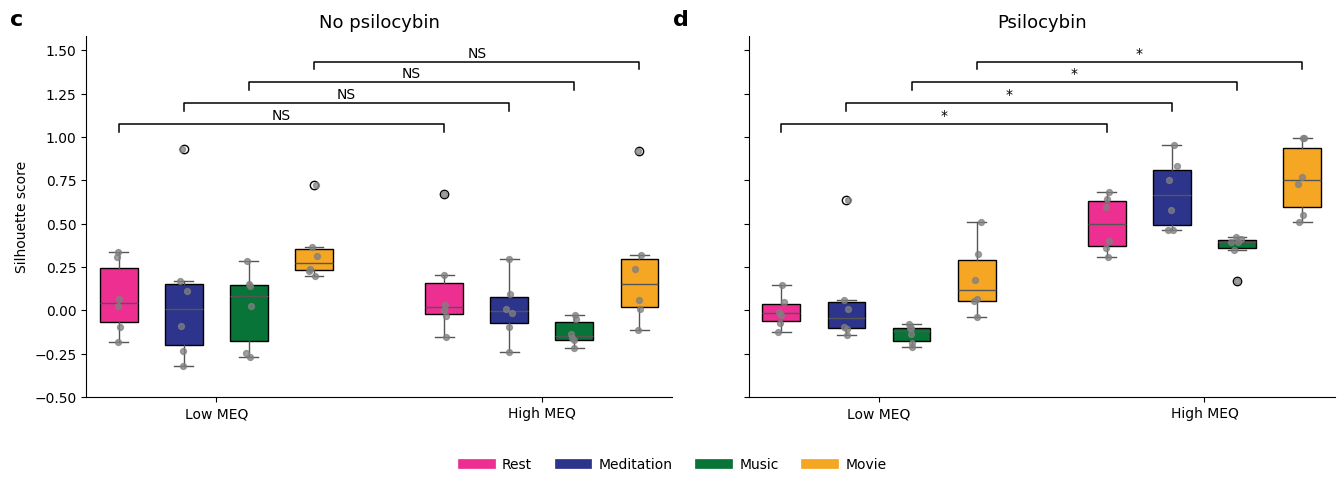

,Condition,Phase,LowMean,HighMean,WelchT,PValue
0,No psilocybin,Rest,0.0760,0.1209,-0.3044,0.7677
1,No psilocybin,Meditation,0.0942,0.0093,0.4274,0.6828
2,No psilocybin,Music,0.0140,-0.1258,1.4392,0.1999
3,No psilocybin,Movie,0.3458,0.2391,0.6280,0.5483
4,Psilocybin,Rest,-0.0051,0.4987,-6.5896,0.0002
5,Psilocybin,Meditation,0.0609,0.6746,-4.2137,0.0023
6,Psilocybin,Music,-0.1358,0.3580,-11.1265,0.0000
7,Psilocybin,Movie,0.1832,0.7591,-4.8356,0.0007


In [8]:
silhouette_runs = pd.read_csv(DATA / 'silhouette_repeated_runs.csv')

# Average the ten repeated fits before making participant-level comparisons.
silhouette_subjects = (
    silhouette_runs
    .groupby(['Condition', 'Cohort', 'ParticipantLabel', 'Phase'], as_index=False)['Silhouette']
    .mean()
)

def significance_label(p_value):
    return '*' if p_value < 0.05 else 'NS'

def add_comparison(ax, x1, x2, y, label, height=0.045):
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], color='black', lw=1.1)
    ax.text((x1 + x2) / 2, y + height + 0.008, label,
            ha='center', va='bottom', fontsize=10)

positions = {'Low MEQ': np.arange(1, 5), 'High MEQ': np.arange(6, 10)}
rng = np.random.default_rng(20261005)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
statistics = []

for panel, (ax, condition) in enumerate(zip(axes, CONDITIONS)):
    condition_data = silhouette_subjects[silhouette_subjects['Condition'].eq(condition)]
    plotted = []
    colors = []
    all_positions = []
    for cohort in ['Low MEQ', 'High MEQ']:
        for phase, position in zip(PHASES, positions[cohort]):
            values = condition_data[
                condition_data['Cohort'].eq(cohort) & condition_data['Phase'].eq(phase)
            ]['Silhouette'].to_numpy()
            plotted.append(values); colors.append(PHASE_COLORS[phase]); all_positions.append(position)

    boxes = ax.boxplot(plotted, positions=all_positions, widths=0.58, patch_artist=True,
                       medianprops={'color': '#555555'},
                       whiskerprops={'color': '#555555'}, capprops={'color': '#555555'})
    for box, color in zip(boxes['boxes'], colors):
        box.set(facecolor=color, edgecolor='black', linewidth=1.0)
    for position, values in zip(all_positions, plotted):
        jitter = rng.normal(0, 0.035, size=len(values))
        ax.scatter(position + jitter, values, color='grey', alpha=0.75, s=18, zorder=3)

    for phase_index, phase in enumerate(PHASES):
        low = condition_data[
            condition_data['Cohort'].eq('Low MEQ') & condition_data['Phase'].eq(phase)
        ]['Silhouette'].to_numpy()
        high = condition_data[
            condition_data['Cohort'].eq('High MEQ') & condition_data['Phase'].eq(phase)
        ]['Silhouette'].to_numpy()
        test = ttest_ind(low, high, equal_var=False)
        statistics.append({'Condition': condition, 'Phase': phase.capitalize(),
                           'LowMean': low.mean(), 'HighMean': high.mean(),
                           'WelchT': test.statistic, 'PValue': test.pvalue})
        add_comparison(ax, positions['Low MEQ'][phase_index], positions['High MEQ'][phase_index],
                       1.03 + phase_index * 0.12, significance_label(test.pvalue))

    ax.set_title(condition, fontsize=13)
    ax.set_xticks([2.5, 7.5], ['Low MEQ', 'High MEQ'])
    ax.set_ylim(-0.5, 1.58)
    ax.set_ylabel('Silhouette score' if panel == 0 else '')
    ax.text(-0.13, 1.03, 'c' if panel == 0 else 'd', transform=ax.transAxes,
            fontsize=16, fontweight='bold')

legend = [Line2D([0], [0], color=PHASE_COLORS[p], lw=7, label=label)
          for p, label in zip(PHASES, PHASE_LABELS)]
fig.legend(handles=legend, frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUTPUT / 'figure_silhouette_low_high_meq.png', dpi=300, bbox_inches='tight')
plt.show()

silhouette_statistics = pd.DataFrame(statistics)
silhouette_statistics.to_csv(OUTPUT / 'silhouette_group_statistics.csv', index=False)
display(silhouette_statistics.round(4))

## Stability across repeated CEBRA fits

Run-to-run variability was summarized for the same 12 participants using the ten repeated Psilocybin CEBRA fits. For every participant and experimental condition, the standard deviation and median absolute deviation (MAD) of the silhouette score were calculated across repeats; the bars show the mean of each variability measure across the four conditions. Participants are ordered by increasing MEQ score.

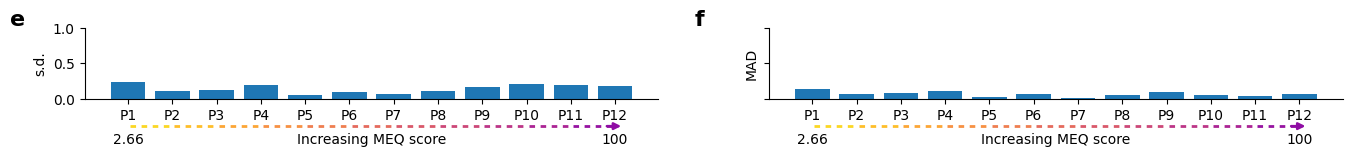

In [9]:
def median_absolute_deviation(values):
    values = np.asarray(values, dtype=float)
    median = np.median(values)
    return float(np.median(np.abs(values - median)))

participant_order = [f'P{i}' for i in range(1, 13)]
psilocybin_runs = silhouette_runs[silhouette_runs['Condition'].eq('Psilocybin')].copy()

phase_stability = (
    psilocybin_runs
    .groupby(['ParticipantLabel', 'Phase'])['Silhouette']
    .agg(SD=lambda x: np.std(x, ddof=1), MAD=median_absolute_deviation)
    .reset_index()
)
participant_stability = (
    phase_stability
    .groupby('ParticipantLabel')[['SD', 'MAD']]
    .mean()
    .reindex(participant_order)
    .reset_index()
)
participant_stability.to_csv(OUTPUT / 'silhouette_run_stability.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.6), sharey=True)
metrics = [('SD', 's.d.', 'e'), ('MAD', 'MAD', 'f')]
x = np.arange(12)

for ax, (column, ylabel, panel) in zip(axes, metrics):
    ax.bar(x, participant_stability[column], width=0.78, color='#1f77b4')
    ax.set_xticks(x, participant_stability['ParticipantLabel'])
    ax.set_ylim(0, 1.0)
    ax.set_ylabel(ylabel)
    ax.text(-0.13, 1.03, panel, transform=ax.transAxes, fontsize=16, fontweight='bold')

    # Dashed colour-gradient arrow and MEQ range annotation.
    gradient = plt.get_cmap('plasma')
    for segment in range(11):
        ax.plot([segment + 0.05, segment + 0.95], [-0.38, -0.38],
                transform=ax.get_xaxis_transform(), clip_on=False,
                color=gradient(0.92 - 0.60 * segment / 10), lw=2, ls=(0, (2, 2)))
    ax.annotate('', xy=(11.2, -0.38), xytext=(10.75, -0.38),
                xycoords=ax.get_xaxis_transform(), textcoords=ax.get_xaxis_transform(),
                arrowprops=dict(arrowstyle='-|>', color=gradient(0.30), lw=1.8),
                annotation_clip=False)
    ax.text(0, -0.56, '2.66',
            transform=ax.get_xaxis_transform(), ha='center', va='center')
    ax.text(5.5, -0.56, 'Increasing MEQ score',
            transform=ax.get_xaxis_transform(), ha='center', va='center')
    ax.text(11, -0.56, '100',
            transform=ax.get_xaxis_transform(), ha='center', va='center')

fig.tight_layout(rect=(0, 0.20, 1, 1), w_pad=3.5)
fig.savefig(OUTPUT / 'figure_silhouette_run_stability.png', dpi=300, bbox_inches='tight')
plt.show()



## Behavioural associations

Psilocybin-session classification accuracy is related to the acute-experience scales reported in the paper. Records are joined by participant ID. Pearson correlations and two-sided uncorrected p-values are reported; the fitted line is descriptive and the shaded band is a 95% bootstrap confidence interval.

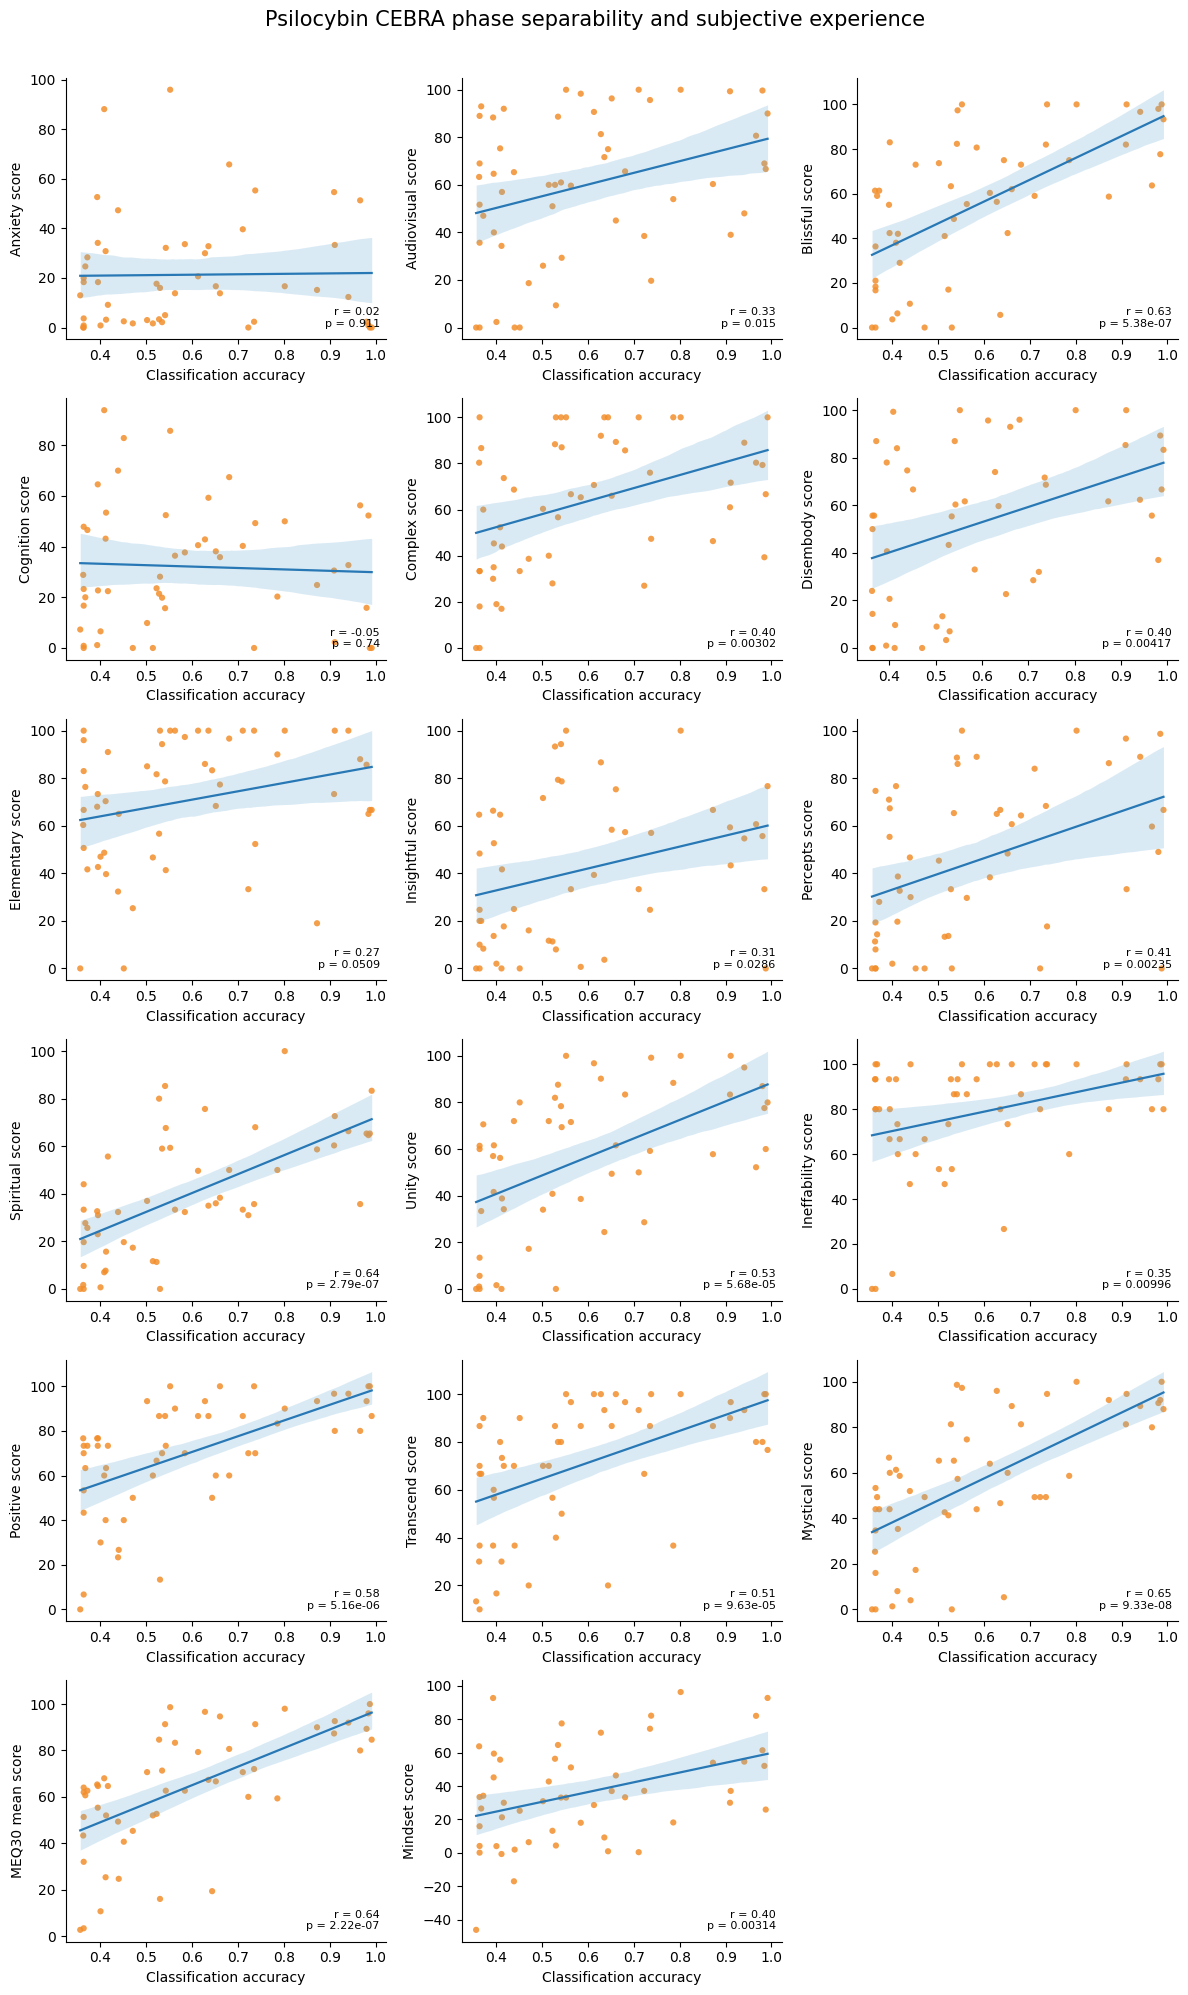

In [10]:
additional = pd.read_csv(DATA / 'Additional_metrics.tsv', sep='\t')
additional['Participant'] = additional['participant_id'].str.extract(r'(PC\d+)')[0]
followup = pd.read_csv(DATA / 'followup-1day.tsv', sep='\t')
followup['Participant'] = followup['participant_id'].str.extract(r'(PC\d+)')[0]

asc_columns = [
    ('ASC11_ANXIETY', 'Anxiety'), ('ASC11_AUDIOVISUAL', 'Audiovisual'),
    ('ASC11_BLISSFUL', 'Blissful'), ('ASC11_COGNITION', 'Cognition'),
    ('ASC11_COMPLEX', 'Complex'), ('ASC11_DISEMBODY', 'Disembody'),
    ('ASC11_ELEMENTARY', 'Elementary'), ('ASC11_INSIGHTFUL', 'Insightful'),
    ('ASC11_PERCEPTS', 'Percepts'), ('ASC11_SPIRITUAL', 'Spiritual'),
    ('ASC11_UNITY', 'Unity')
]
meq_columns = [
    ('MEQ30_INEFFABILITY', 'Ineffability'), ('MEQ30_POSITIVE', 'Positive'),
    ('MEQ30_TRANSCEND', 'Transcend'), ('MEQ30_MYSTICAL', 'Mystical')
]
missing_scales = [c for c, _ in asc_columns + meq_columns if c not in additional.columns]
if missing_scales:
    raise KeyError(f'Missing behavioural columns: {missing_scales}')

behaviour = additional[['Participant'] + [c for c, _ in asc_columns + meq_columns]].copy()
behaviour = behaviour.drop_duplicates('Participant')
behaviour = behaviour.merge(meq.rename(columns={'MEQ30_MEAN': 'MEQ30 mean'}), on='Participant', how='outer')

mindset_columns = [c for c in followup.columns if c.startswith('EXP.MINDSET_')]
mindset_numeric = followup[mindset_columns].apply(pd.to_numeric, errors='coerce')
mindset = pd.DataFrame({'Participant': followup['Participant'],
                        'Mindset': mindset_numeric.mean(axis=1)}).dropna(subset=['Participant'])
mindset = mindset.drop_duplicates('Participant')
behaviour = behaviour.merge(mindset, on='Participant', how='outer')

psilocybin_accuracy = results[results['Session'].eq('Psilocybin')][['Participant', 'Accuracy']]
analysis = psilocybin_accuracy.merge(behaviour, on='Participant', how='left', validate='one_to_one')

plot_scales = asc_columns[:11] + meq_columns[:2] + [
    ('MEQ30_TRANSCEND', 'Transcend'), ('MEQ30_MYSTICAL', 'Mystical'),
    ('MEQ30 mean', 'MEQ30 mean'), ('Mindset', 'Mindset')
]

def regression_panel(ax, frame, column, label, rng):
    clean = frame[['Accuracy', column]].apply(pd.to_numeric, errors='coerce').dropna()
    x, y = clean['Accuracy'].to_numpy(), clean[column].to_numpy()
    r, p = pearsonr(x, y)
    ax.scatter(x, y, s=20, color='#f28e2b', alpha=0.85, edgecolors='none')
    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 150)
    fitted = np.polyval(coef, xx)
    ax.plot(xx, fitted, color='#2878b5', lw=1.6)
    boot = []
    for _ in range(1000):
        idx = rng.integers(0, len(x), len(x))
        if np.ptp(x[idx]) > 0:
            boot.append(np.polyval(np.polyfit(x[idx], y[idx], 1), xx))
    if boot:
        lo, hi = np.percentile(np.asarray(boot), [2.5, 97.5], axis=0)
        ax.fill_between(xx, lo, hi, color='#6baed6', alpha=0.25, linewidth=0)
    ax.set(xlabel='Classification accuracy', ylabel=f'{label} score')
    ax.text(0.98, 0.04, f'r = {r:.2f}\np = {p:.3g}', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=8)
    return {'Outcome': label, 'Column': column, 'N': len(clean), 'PearsonR': round(r, 2), 'PValue': p}

rng = np.random.default_rng(20261005)
fig, axes = plt.subplots(6, 3, figsize=(12, 20))
stats = []
for ax, (column, label) in zip(axes.flat, plot_scales):
    stats.append(regression_panel(ax, analysis, column, label, rng))
for ax in axes.flat[len(plot_scales):]:
    ax.axis('off')
fig.suptitle('Psilocybin CEBRA phase separability and subjective experience', fontsize=15, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.988))
fig.savefig(OUTPUT / 'figure_behaviour_correlations.png', dpi=300, bbox_inches='tight')
plt.show()

behaviour_correlations = pd.DataFrame(stats)
behaviour_correlations.to_csv(OUTPUT / 'behaviour_correlations.csv', index=False)


## Animated Psilocybin embeddings

The animations compares two participants from each end of the MEQ distribution. 

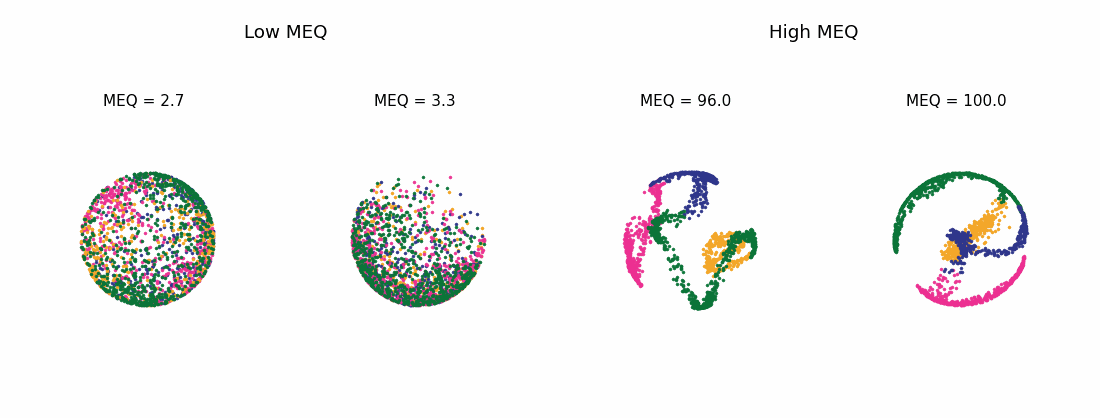

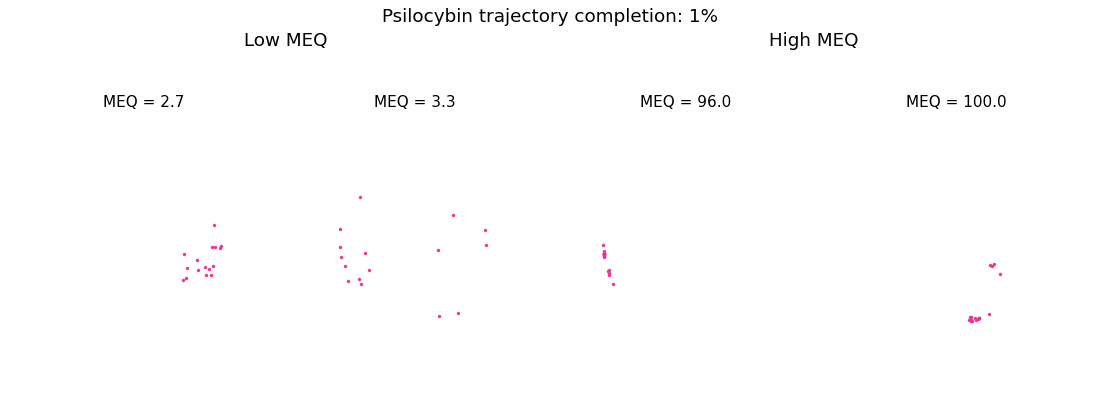

In [12]:
gif_ids = ['PC008', 'PC203', 'PC233', 'PC209']

# Rotating completed trajectories.
fig = plt.figure(figsize=(10, 3.8))
gif_axes = []
for col, pid in enumerate(gif_ids):
    ax = fig.add_subplot(1, 4, col + 1, projection='3d')
    scatter_embedding(ax, pid, 'Psilocybin', point_size=1.8, alpha=0.85)
    ax.set_title(f'MEQ = {meq_map[pid]:.1f}', fontsize=10)
    gif_axes.append(ax)
fig.text(0.26, 0.91, 'Low MEQ', ha='center', fontsize=12)
fig.text(0.74, 0.91, 'High MEQ', ha='center', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.84))

def rotate(angle):
    for ax in gif_axes:
        ax.view_init(elev=18, azim=angle)
    return gif_axes

rotation = FuncAnimation(fig, rotate, frames=np.arange(0, 360, 4), interval=70, blit=False)
rotation_path = OUTPUT / 'CEBRA_psilocybin_low_high_rotation.gif'
rotation.save(rotation_path, writer=PillowWriter(fps=15), dpi=110)
plt.close(fig)
display(Image(filename=str(rotation_path)))

# Temporal progression: points appear in their recorded order.
fig = plt.figure(figsize=(10, 3.8))
progress_axes = [fig.add_subplot(1, 4, i + 1, projection='3d') for i in range(4)]
limits = {}
for pid in gif_ids:
    embedding = embeddings['Psilocybin'][pid]
    limits[pid] = [(embedding[:, dim].min(), embedding[:, dim].max()) for dim in range(3)]
fig.text(0.26, 0.89, 'Low MEQ', ha='center', fontsize=12)
fig.text(0.74, 0.89, 'High MEQ', ha='center', fontsize=12)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.03, top=0.78, wspace=0.02)

def show_progress(frame):
    fraction = (frame + 1) / 120
    for ax, pid in zip(progress_axes, gif_ids):
        ax.cla()
        embedding = embeddings['Psilocybin'][pid]
        labels = phase_labels(phase_durations(pid, 'Psilocybin'))
        n_visible = max(1, int(fraction * len(embedding)))
        for label, phase in enumerate(PHASES):
            visible = np.arange(len(embedding)) < n_visible
            points = embedding[(labels == label) & visible]
            if len(points):
                ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=1.8,
                           color=PHASE_COLORS[phase], alpha=0.85, depthshade=False)
        ax.set_xlim(*limits[pid][0]); ax.set_ylim(*limits[pid][1]); ax.set_zlim(*limits[pid][2])
        ax.set_axis_off(); ax.set_box_aspect((1, 1, 1))
        ax.set_title(f'MEQ = {meq_map[pid]:.1f}', fontsize=10)
    fig.suptitle(f'Psilocybin trajectory completion: {fraction:.0%}', fontsize=12, y=0.98)
    return progress_axes

progression = FuncAnimation(fig, show_progress, frames=120, interval=60, blit=False)
progression_path = OUTPUT / 'CEBRA_psilocybin_low_high_temporal_progression.gif'
progression.save(progression_path, writer=PillowWriter(fps=18), dpi=110)
plt.close(fig)
display(Image(filename=str(progression_path)))

## Network-attributed decomposition of classification gain

For six representative participants, the saved original and network-perturbed classification accuracies are used to calculate the perturbation-induced accuracy drops. These drops are then summarized as a normalized mean profile, an average no-psilocybin-to-psilocybin accuracy decomposition, and participant-level contribution compositions.


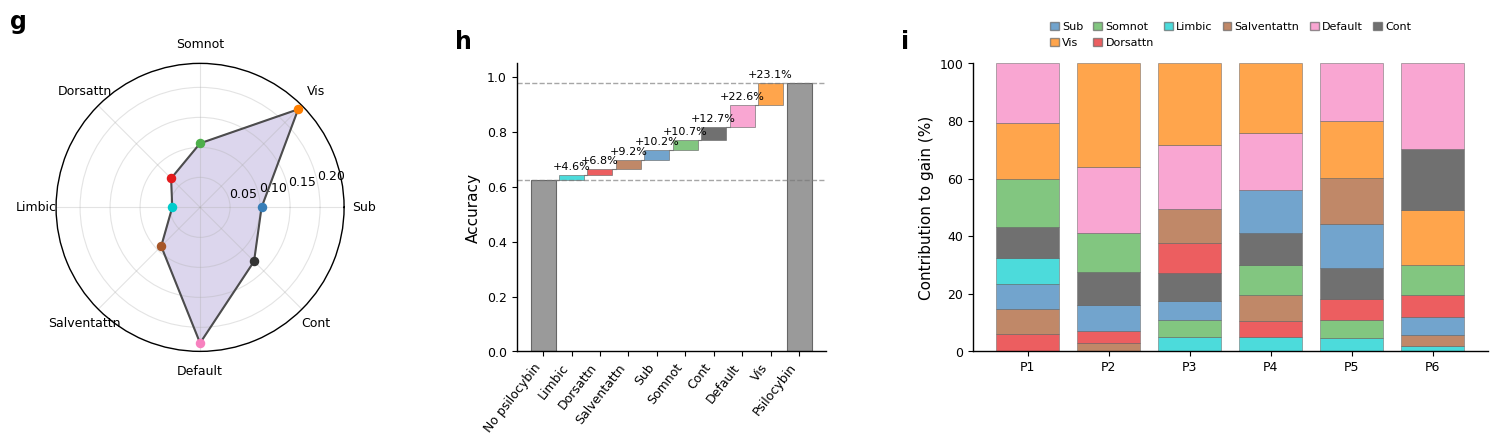

,Network,MeanContribution,PercentOfMeanGain
0,Sub,0.036187,10.246381
1,Vis,0.081630,23.113802
2,Somnot,0.037704,10.676034
3,Dorsattn,0.024118,6.829139
4,Limbic,0.016380,4.637931
5,Salventattn,0.032361,9.163169
6,Default,0.079862,22.613053
7,Cont,0.044925,12.720493


In [11]:
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

network_data = pd.read_csv(DATA / 'network_perturbation_accuracies.csv')
network_columns = ['Sub', 'Vis', 'SomMot', 'DorsAttn', 'Limbic',
                   'SalVentAttn', 'Default', 'Cont']
perturbed_columns = [f'{network}PerturbedAccuracy' for network in network_columns]
required = ['ParticipantLabel', 'StoredSubjectIndex', 'NoPsilocybinAccuracy',
            'PsilocybinAccuracy'] + perturbed_columns
if network_data.columns.tolist() != required:
    raise ValueError('Unexpected columns in network_perturbation_accuracies.csv')
if len(network_data) != 6:
    raise ValueError('Expected six participants in the perturbation results.')

no_psilocybin_accuracy = network_data['NoPsilocybinAccuracy'].to_numpy(dtype=float)
psilocybin_accuracy = network_data['PsilocybinAccuracy'].to_numpy(dtype=float)
perturbed_accuracy = network_data[perturbed_columns].to_numpy(dtype=float)

# Accuracy loss after replacing each psilocybin network with its no-psilocybin
# time series. Multiplication by 100 expresses the loss in percentage points.
drops = (psilocybin_accuracy[:, None] - perturbed_accuracy) * 100
gain = psilocybin_accuracy - no_psilocybin_accuracy

# Positive perturbation effects determine the relative network weights.
positive_drops = np.clip(drops, 0, None)
weights = np.divide(
    positive_drops,
    positive_drops.sum(axis=1, keepdims=True),
    out=np.zeros_like(positive_drops),
    where=positive_drops.sum(axis=1, keepdims=True) > 0,
)
contribution = weights * gain[:, None]
participant_percent = weights * 100

no_psilocybin_mean = float(no_psilocybin_accuracy.mean())
psilocybin_mean = float(psilocybin_accuracy.mean())
gain_mean = psilocybin_mean - no_psilocybin_mean
contribution_mean = contribution.mean(axis=0)
mean_profile = contribution_mean / gain_mean

# Validate the values printed in the original panels.
expected_percent = np.array([10.2, 23.1, 10.7, 6.8, 4.6, 9.2, 22.6, 12.7])
np.testing.assert_allclose(mean_profile * 100, expected_percent, atol=0.06)
np.testing.assert_allclose([no_psilocybin_mean, psilocybin_mean], [0.625, 0.9781666667], atol=1e-10)

network_labels = ['Sub', 'Vis', 'Somnot', 'Dorsattn', 'Limbic',
                  'Salventattn', 'Default', 'Cont']
network_colors = ['#377eb8', '#ff7f00', '#4daf4a', '#e41a1c',
                  '#00cccc', '#a65628', '#f781bf', '#333333']
color_map = dict(zip(network_columns, network_colors))

with plt.rc_context({
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
    'font.size': 10, 'axes.labelsize': 11, 'xtick.labelsize': 9,
    'ytick.labelsize': 9, 'axes.linewidth': 1.0,
}):
    fig = plt.figure(figsize=(15.5, 4.8))
    grid = GridSpec(1, 3, figure=fig, width_ratios=[1.15, 1.05, 1.75], wspace=0.38)

    # g: normalized mean network-contribution profile.
    ax_g = fig.add_subplot(grid[0, 0], projection='polar')
    angles = np.linspace(0, 2 * np.pi, len(network_columns), endpoint=False)
    closed_angles = np.r_[angles, angles[0]]
    closed_values = np.r_[mean_profile, mean_profile[0]]
    ax_g.plot(closed_angles, closed_values, color='#4c4c4c', lw=1.5)
    ax_g.fill(closed_angles, closed_values, color='#8d79c6', alpha=0.30)
    for angle, value, color in zip(angles, mean_profile, network_colors):
        ax_g.scatter(angle, value, s=34, color=color, zorder=3)
    ax_g.set_xticks(angles)
    ax_g.set_xticklabels(network_labels)
    ax_g.set_ylim(0, 0.24)
    ax_g.set_yticks([0.05, 0.10, 0.15, 0.20])
    ax_g.set_yticklabels(['0.05', '0.10', '0.15', '0.20'])
    ax_g.set_rlabel_position(12)
    ax_g.grid(alpha=0.35)
    ax_g.text(-0.16, 1.12, 'g', transform=ax_g.transAxes,
              fontsize=17, fontweight='bold')

    # h: average waterfall from no psilocybin to psilocybin accuracy.
    ax_h = fig.add_subplot(grid[0, 1])
    order = np.argsort(contribution_mean)
    waterfall_labels = ['No psilocybin'] + [network_labels[i] for i in order] + ['Psilocybin']
    xx = np.arange(len(waterfall_labels))
    ax_h.bar(xx[0], no_psilocybin_mean, width=0.88, color='#9a9a9a',
             edgecolor='#666666', linewidth=0.8)
    running = no_psilocybin_mean
    for position, network_index in enumerate(order, start=1):
        value = contribution_mean[network_index]
        ax_h.bar(position, value, bottom=running, width=0.88,
                 color=network_colors[network_index], alpha=0.70,
                 edgecolor='#666666', linewidth=0.6)
        ax_h.plot([position - 1 + 0.44, position - 0.44], [running, running],
                  color='#777777', lw=0.8)
        ax_h.text(position, running + value + 0.012,
                  f'+{100 * value / gain_mean:.1f}%',
                  ha='center', va='bottom', fontsize=8)
        running += value
    ax_h.bar(xx[-1], psilocybin_mean, width=0.88, color='#9a9a9a',
             edgecolor='#666666', linewidth=0.8)
    ax_h.axhline(no_psilocybin_mean, color='#777777', ls='--', lw=1, alpha=0.65)
    ax_h.axhline(psilocybin_mean, color='#777777', ls='--', lw=1, alpha=0.65)
    ax_h.set_xticks(xx)
    ax_h.set_xticklabels(waterfall_labels, rotation=52, ha='right')
    ax_h.set_ylabel('Accuracy')
    ax_h.set_ylim(0, 1.05)
    ax_h.spines[['top', 'right']].set_visible(False)
    ax_h.text(-0.20, 1.05, 'h', transform=ax_h.transAxes,
              fontsize=17, fontweight='bold')

    # i: participant-wise composition of the attributed gain.
    ax_i = fig.add_subplot(grid[0, 2])
    x = np.arange(len(network_data))
    for participant_index in range(len(network_data)):
        bottom = 0.0
        for network_index in np.argsort(participant_percent[participant_index]):
            value = participant_percent[participant_index, network_index]
            if value <= 0:
                continue
            ax_i.bar(x[participant_index], value, bottom=bottom, width=0.78,
                     color=network_colors[network_index], alpha=0.70,
                     edgecolor='#666666', linewidth=0.5)
            bottom += value
    ax_i.set_xticks(x)
    ax_i.set_xticklabels(network_data['ParticipantLabel'])
    ax_i.set_ylabel('Contribution to gain (%)')
    ax_i.set_ylim(0, 100)
    ax_i.spines[['top', 'right']].set_visible(False)
    legend_handles = [Patch(facecolor=color, edgecolor='#666666', alpha=0.70,
                            label=label)
                      for label, color in zip(network_labels, network_colors)]
    ax_i.legend(handles=legend_handles, frameon=False, ncol=6,
                loc='lower center', bbox_to_anchor=(0.5, 1.02),
                fontsize=8, columnspacing=0.9, handlelength=0.8,
                handletextpad=0.3)
    ax_i.text(-0.14, 1.05, 'i', transform=ax_i.transAxes,
              fontsize=17, fontweight='bold')

    fig.subplots_adjust(left=0.055, right=0.995, bottom=0.22, top=0.82)
    figure_path = OUTPUT / 'figure_network_attribution_g_h_i.png'
    fig.savefig(figure_path, dpi=300, bbox_inches='tight')
    plt.show()

network_summary = pd.DataFrame({
    'Network': network_labels,
    'MeanContribution': contribution_mean,
    'PercentOfMeanGain': mean_profile * 100,
})
network_summary.to_csv(OUTPUT / 'network_attribution_summary.csv', index=False)
display(network_summary)


### Condition-specific recall after network substitution

Extended Data Fig. 7b reports the change in phase-specific recall after replacing each psilocybin network trajectory with its no-psilocybin counterpart. The supplied file contains the original row-normalized confusion matrices for the six participants: one reference matrix and eight network-substitution matrices per participant. Recall is the diagonal of each matrix; the plotted value is reference recall minus substituted recall, averaged across participants.

The retained overall perturbation accuracies and condition-specific confusion matrices were generated during separate executions of the same CEBRA workflow. Small numerical differences between them are therefore expected because of CEBRA stochasticity.

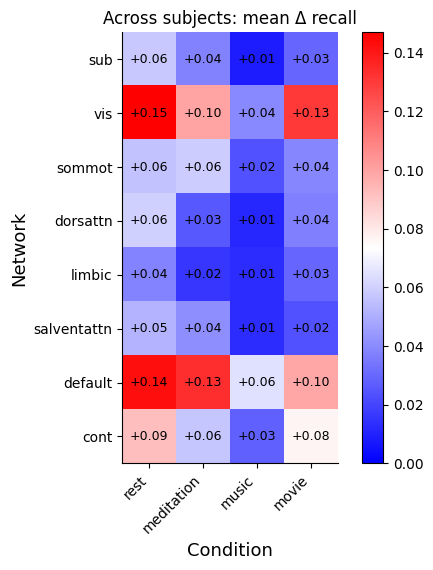

,rest,meditation,music,movie
sub,0.0574,0.0375,0.0085,0.0295
vis,0.1470,0.0996,0.0392,0.1304
sommot,0.0561,0.0587,0.0240,0.0386
dorsattn,0.0598,0.0254,0.0111,0.0372
limbic,0.0384,0.0158,0.0127,0.0295
salventattn,0.0518,0.0412,0.0131,0.0236
default,0.1426,0.1338,0.0643,0.0990
cont,0.0919,0.0571,0.0277,0.0767


In [12]:
with np.load(DATA / 'network_perturbation_confusion_matrices.npz') as recall_input:
    recall_subject_indices = recall_input['stored_subject_indices']
    recall_participants = recall_input['participant_ids'].astype(str)
    recall_networks = recall_input['network_names'].astype(str)
    recall_phases = recall_input['phase_names'].astype(str)
    reference_confusion = recall_input['psilocybin_reference'].astype(float)
    substituted_confusion = recall_input['network_substituted'].astype(float)

if reference_confusion.shape != (6, 4, 4):
    raise ValueError(f'Unexpected reference matrix shape: {reference_confusion.shape}')
if substituted_confusion.shape != (6, 8, 4, 4):
    raise ValueError(f'Unexpected substituted matrix shape: {substituted_confusion.shape}')
np.testing.assert_allclose(reference_confusion.sum(axis=-1), 1.0, atol=1e-12)
np.testing.assert_allclose(substituted_confusion.sum(axis=-1), 1.0, atol=1e-12)

# Per-condition recall is the diagonal of a row-normalized confusion matrix.
reference_recall = np.diagonal(reference_confusion, axis1=-2, axis2=-1)
substituted_recall = np.diagonal(substituted_confusion, axis1=-2, axis2=-1)
delta_recall = reference_recall[:, None, :] - substituted_recall
mean_delta_recall = delta_recall.mean(axis=0)
sem_delta_recall = delta_recall.std(axis=0, ddof=1) / np.sqrt(len(delta_recall))

# Preserve the participant-level inputs and calculated values in a tidy table.
recall_rows = []
for subject_index, participant in enumerate(recall_participants):
    for network_index, network in enumerate(recall_networks):
        for phase_index, phase in enumerate(recall_phases):
            recall_rows.append({
                'Participant': participant,
                'StoredSubjectIndex': int(recall_subject_indices[subject_index]),
                'Network': network,
                'Condition': phase,
                'PsilocybinRecall': reference_recall[subject_index, phase_index],
                'SubstitutedRecall': substituted_recall[subject_index, network_index, phase_index],
                'DeltaRecall': delta_recall[subject_index, network_index, phase_index],
            })
recall_results = pd.DataFrame(recall_rows)
recall_results.to_csv(OUTPUT / 'network_condition_recall_changes.csv', index=False)

fig, ax = plt.subplots(figsize=(5.2, 5.8))
colour_limit = float(np.max(np.abs(mean_delta_recall)))
image = ax.imshow(mean_delta_recall, cmap='bwr', vmin=0, vmax=colour_limit)
ax.set_xticks(np.arange(len(recall_phases)), recall_phases, rotation=45, ha='right')
ax.set_yticks(np.arange(len(recall_networks)), recall_networks)
ax.set_xlabel('Condition', fontsize=13)
ax.set_ylabel('Network', fontsize=13)
ax.set_title('Across subjects: mean Δ recall', fontsize=12)
for network_index in range(len(recall_networks)):
    for phase_index in range(len(recall_phases)):
        ax.text(phase_index, network_index,
                f'{mean_delta_recall[network_index, phase_index]:+.2f}',
                ha='center', va='center', fontsize=9)
fig.colorbar(image, ax=ax)

fig.tight_layout()
recall_figure_path = OUTPUT / 'extended_figure_7b_condition_recall.png'
fig.savefig(recall_figure_path, dpi=300, bbox_inches='tight')
plt.show()

recall_summary = pd.DataFrame(
    mean_delta_recall, index=recall_networks, columns=recall_phases
)
recall_summary.to_csv(OUTPUT / 'network_condition_mean_delta_recall.csv')
display(recall_summary.round(4))


### Network organization

The panels below show group-average TAVRNN representations for participants at the high and low ends of the MEQ distribution. The supplied two-dimensional embeddings are the fixed projections used for these analyses; network-distance heatmaps are calculated directly from those coordinates.


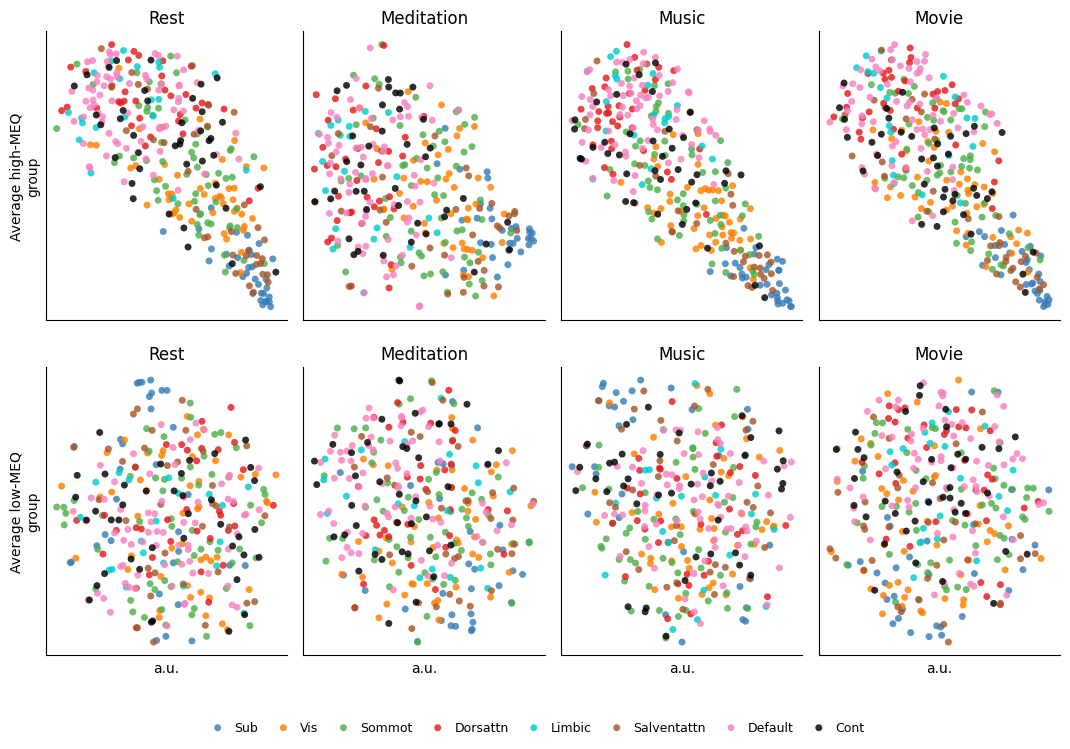

In [13]:
from sklearn.manifold import TSNE

tavrnn = np.load(DATA / 'tavrnn_group_mean_embeddings.npz')
tavrnn_phases = tavrnn['phases'].tolist()
tavrnn_network_labels = tavrnn['network_labels']
tavrnn_network_names = [
    'Sub', 'Vis', 'Sommot', 'Dorsattn',
    'Limbic', 'Salventattn', 'Default', 'Cont'
]
tavrnn_network_colors = [
    '#377eb8', '#ff7f00', '#4daf4a', '#e41a1c',
    '#00cccc', '#a65628', '#f781bf', '#000000'
]

def tavrnn_tsne(embedding):
    return TSNE(
        n_components=2, perplexity=40, random_state=20,
        init='pca', learning_rate='auto', max_iter=1000,
    ).fit_transform(embedding)

tavrnn_2d = {
    group: np.stack([tavrnn_tsne(embedding) for embedding in tavrnn[group]])
    for group in ['high_meq', 'low_meq']
}

# Rigid rotations reproduce the published panel orientation. They do not
# alter relative geometry or numerical values.
display_angles = {'high_meq': [90, 0, -135, 135],
                  'low_meq': [0, 0, 0, 0]}
def rotate_coordinates(coordinates, degrees):
    radians = np.deg2rad(degrees)
    rotation = np.array([[np.cos(radians), -np.sin(radians)],
                         [np.sin(radians),  np.cos(radians)]])
    centered = coordinates - coordinates.mean(axis=0, keepdims=True)
    return centered @ rotation.T

def orient_blue_lower_right(coordinates, network_labels):
    coordinates = coordinates.copy()
    blue_centroid = coordinates[network_labels == 0].mean(axis=0)
    if blue_centroid[0] < 0:
        coordinates[:, 0] *= -1
    if blue_centroid[1] > 0:
        coordinates[:, 1] *= -1
    return coordinates

fig, axes = plt.subplots(2, 4, figsize=(10.8, 7.4))
for row, (array_name, group_label) in enumerate([
    ('high_meq', 'Average high-MEQ\ngroup'),
    ('low_meq', 'Average low-MEQ\ngroup'),
]):
    for column, phase in enumerate(tavrnn_phases):
        ax = axes[row, column]
        coordinates = rotate_coordinates(
            tavrnn_2d[array_name][column],
            display_angles[array_name][column],
        )
        if array_name == 'high_meq' and column == 0:
            coordinates = orient_blue_lower_right(
                coordinates, tavrnn_network_labels
            )
        for network, (name, color) in enumerate(
            zip(tavrnn_network_names, tavrnn_network_colors)
        ):
            points = coordinates[tavrnn_network_labels == network]
            ax.scatter(points[:, 0], points[:, 1], s=25, color=color,
                       alpha=0.82, edgecolors='none', label=name)
        ax.set_title(phase)
        ax.set_xticks([]); ax.set_yticks([])
        if column == 0:
            ax.set_ylabel(group_label)
        if row == 1:
            ax.set_xlabel('a.u.')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=8, frameon=False,
           bbox_to_anchor=(0.5, -0.015), columnspacing=1.0,
           handletextpad=0.35, fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1), w_pad=1.2, h_pad=1.8)
fig.savefig(OUTPUT / 'figure_tavrnn_group_embeddings.png', dpi=300,
            bbox_inches='tight')
plt.show()


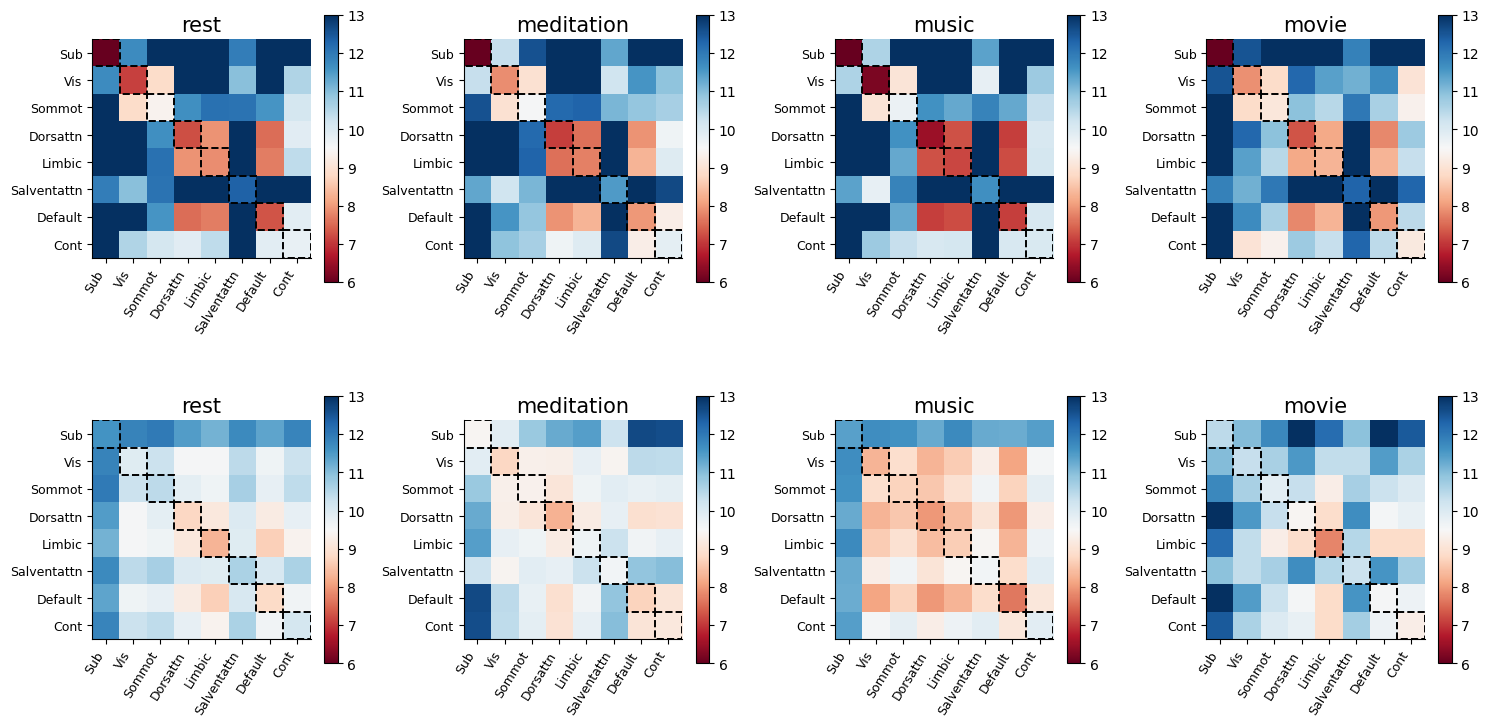

In [14]:
from scipy.spatial.distance import cdist

def network_distance_matrix(coordinates, network_labels, n_networks=8):
    distances = cdist(coordinates, coordinates, metric='euclidean')
    matrix = np.empty((n_networks, n_networks), dtype=float)
    for first in range(n_networks):
        first_indices = np.flatnonzero(network_labels == first)
        for second in range(n_networks):
            second_indices = np.flatnonzero(network_labels == second)
            matrix[first, second] = distances[np.ix_(
                first_indices, second_indices
            )].mean()
    return matrix

fig, axes = plt.subplots(2, 4, figsize=(15, 7.8))
for row, array_name in enumerate(['high_meq', 'low_meq']):
    for column, phase in enumerate(tavrnn_phases):
        ax = axes[row, column]
        matrix = network_distance_matrix(
            tavrnn_2d[array_name][column], tavrnn_network_labels
        )
        image = ax.imshow(matrix, cmap='RdBu', interpolation='nearest',
                          vmin=6, vmax=13)
        for diagonal in range(8):
            ax.add_patch(plt.Rectangle(
                (diagonal - 0.5, diagonal - 0.5), 1, 1,
                edgecolor='black', linewidth=1.4, linestyle='--',
                facecolor='none'
            ))
        ax.set_title(phase.lower(), fontsize=15)
        ax.set_xticks(range(8), tavrnn_network_names,
                      rotation=58, ha='right', fontsize=9)
        ax.set_yticks(range(8), tavrnn_network_names, fontsize=9)
        fig.colorbar(image, ax=ax, shrink=0.82, ticks=np.arange(6, 14))

fig.tight_layout(w_pad=1.1, h_pad=1.7)
fig.savefig(OUTPUT / 'figure_tavrnn_network_distance_heatmaps.png',
            dpi=300, bbox_inches='tight')
plt.show()
